# Computer Vision Assignment 1 — Hand Gesture Recognition on a Self-Collected Dataset

**Student:** Shynbergen Yegizbayev

**Task:** classify hand gestures (`peace`, `stop`, `thumbs_up`) from photos.

**Pipeline:** data collection (own phone videos → frames) → preprocessing and augmentation → baseline model (simple CNN) → transfer learning with MobileNetV2 (frozen, then fine-tuned) → evaluation and comparison.

> Before running: `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

## 1. Setup

In [ ]:
import os, glob, random, shutil, time
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             accuracy_score, precision_recall_fscore_support)

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Paths and settings
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/cv_assignment'
    DATASET_DIR = '/content/dataset'
except ImportError:
    PROJECT_DIR = './cv_assignment'
    DATASET_DIR = './dataset'

VIDEOS_DIR = f'{PROJECT_DIR}/videos'      # videos/<class_name>/*.mp4
OUT_DIR = f'{PROJECT_DIR}/outputs'        # figures for the report
os.makedirs(OUT_DIR, exist_ok=True)

FRAMES_PER_VIDEO = 35     # 5 videos x 35 frames = 175 images per class
IMG_SIZE = 224
BATCH = 32
EPOCHS_BASELINE = 20
EPOCHS_TRANSFER = 12
EPOCHS_FINETUNE = 25
WEIGHTS = 'imagenet'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data collection

The dataset was collected by me with a phone camera. For every gesture I recorded several short videos in **different places, backgrounds and lighting conditions**, with both hands. Frames are sampled evenly from each video, center-cropped to a square and saved as JPEG images.

In [ ]:
VIDEO_EXT = ('.mp4', '.mov', '.m4v', '.avi', '.mkv')


def extract_frames(video_path, out_dir, prefix, n_frames):
    """Save n_frames evenly spaced, center-cropped frames from one video."""
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        total = 300
    wanted = set(np.linspace(0, total - 1, n_frames).astype(int).tolist())
    saved, i = 0, 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if i in wanted:
            h, w = frame.shape[:2]
            s = min(h, w)
            y0, x0 = (h - s) // 2, (w - s) // 2
            frame = frame[y0:y0 + s, x0:x0 + s]
            frame = cv2.resize(frame, (256, 256), interpolation=cv2.INTER_AREA)
            cv2.imwrite(os.path.join(out_dir, f'{prefix}_f{saved:03d}.jpg'), frame,
                        [cv2.IMWRITE_JPEG_QUALITY, 90])
            saved += 1
        i += 1
    cap.release()
    return saved


if os.path.exists(DATASET_DIR):
    shutil.rmtree(DATASET_DIR)

CLASS_NAMES = sorted(d for d in os.listdir(VIDEOS_DIR)
                     if os.path.isdir(os.path.join(VIDEOS_DIR, d)) and not d.startswith('.'))
print('Classes:', CLASS_NAMES)

for cls in CLASS_NAMES:
    src = os.path.join(VIDEOS_DIR, cls)
    dst = os.path.join(DATASET_DIR, cls)
    os.makedirs(dst, exist_ok=True)
    videos = sorted(f for f in os.listdir(src) if f.lower().endswith(VIDEO_EXT))
    for k, v in enumerate(videos, 1):
        n = extract_frames(os.path.join(src, v), dst, f'{cls}_v{k:02d}', FRAMES_PER_VIDEO)
        print(f'{cls:12s} {v:30s} -> {n} frames')

Classes: ['peace', 'stop', 'thumbs_up']
peace        video5345924876840509445.mp4   -> 35 frames
peace        video5345924876840509447.mp4   -> 35 frames
peace        video5345924876840509454.mp4   -> 35 frames
peace        video5345924876840509456.mp4   -> 35 frames
peace        video5345924876840509459.mp4   -> 35 frames
stop         video5345924876840509449.mp4   -> 35 frames
stop         video5345924876840509450.mp4   -> 35 frames
stop         video5345924876840509452.mp4   -> 35 frames
stop         video5345924876840509453.mp4   -> 35 frames
stop         video5345924876840509457.mp4   -> 35 frames
thumbs_up    video5345924876840509446.mp4   -> 35 frames
thumbs_up    video5345924876840509448.mp4   -> 35 frames
thumbs_up    video5345924876840509451.mp4   -> 35 frames
thumbs_up    video5345924876840509455.mp4   -> 35 frames
thumbs_up    video5345924876840509458.mp4   -> 35 frames


In [ ]:
# Dataset table: one row per image
records = []
for cls in CLASS_NAMES:
    for p in sorted(glob.glob(os.path.join(DATASET_DIR, cls, '*.jpg'))):
        video_id = os.path.basename(p).rsplit('_f', 1)[0]
        records.append({'path': p, 'label': cls, 'video': video_id})
df = pd.DataFrame(records)

NUM_CLASSES = len(CLASS_NAMES)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASS_NAMES)}

print('Total images:', len(df))
print(df.groupby('label').agg(images=('path', 'count'), videos=('video', 'nunique')))

Total images: 525
           images  videos
label                    
peace         175       5
stop          175       5
thumbs_up     175       5


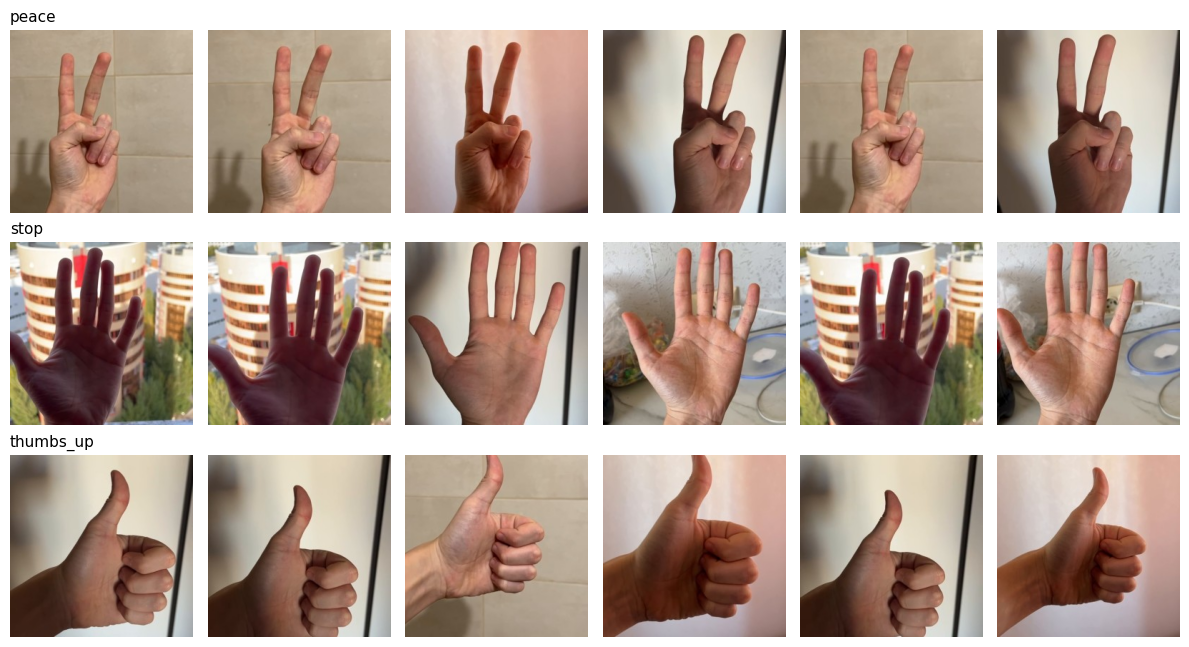

In [ ]:
# Sample images from every class
fig, axes = plt.subplots(NUM_CLASSES, 6, figsize=(12, 2.2 * NUM_CLASSES))
for r, cls in enumerate(CLASS_NAMES):
    sample = df[df.label == cls].sample(6, random_state=SEED)
    for c, p in enumerate(sample.path):
        axes[r, c].imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB))
        axes[r, c].axis('off')
    axes[r, 0].set_title(cls, loc='left', fontsize=11)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/samples.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Train / validation / test split

Frames from the same video look almost identical. If they were split randomly, nearly the same picture would be in both train and test, and the accuracy would be unrealistically high. So the split is done **by video**: for every class one whole video goes to test, one to validation, and the rest to train. The test set therefore contains backgrounds the model has never seen.

In [ ]:
rng = random.Random(SEED)
split_of = {}
for cls in CLASS_NAMES:
    vids = sorted(df[df.label == cls].video.unique())
    assert len(vids) >= 3, f'Class "{cls}" needs at least 3 videos, found {len(vids)}'
    rng.shuffle(vids)
    split_of[vids[0]] = 'test'
    split_of[vids[1]] = 'val'
    for v in vids[2:]:
        split_of[v] = 'train'
df['split'] = df.video.map(split_of)
df.to_csv(f'{OUT_DIR}/splits.csv', index=False)
print(pd.crosstab(df.label, df.split))

split      test  train  val
label                      
peace        35    105   35
stop         35    105   35
thumbs_up    35    105   35


## 4. Preprocessing and augmentation

- **Resizing:** every image is resized to 224×224.
- **Normalization:** pixel values are scaled inside each model (to [0, 1] for the baseline CNN and to [-1, 1] for MobileNetV2).
- **Augmentation (training only):** horizontal flip, rotation, zoom, shift, contrast and brightness changes. This simulates other hand positions, distances and lighting.

In [ ]:
def load_split(name):
    part = df[df.split == name]
    X = np.stack([cv2.cvtColor(cv2.resize(cv2.imread(p), (IMG_SIZE, IMG_SIZE)), cv2.COLOR_BGR2RGB)
                  for p in part.path])
    y = part.label.map(CLASS_TO_IDX).values.astype('int32')
    return X, y


X_train, y_train = load_split('train')
X_val, y_val = load_split('val')
X_test, y_test = load_split('test')
print('train', X_train.shape, '| val', X_val.shape, '| test', X_test.shape)


def to_float(x, y):
    return tf.cast(x, tf.float32), y


train_ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train))
            .shuffle(len(X_train), seed=SEED).batch(BATCH).map(to_float).prefetch(tf.data.AUTOTUNE))
val_ds = tf.data.Dataset.from_tensor_slices((X_val, y_val)).batch(BATCH).map(to_float)
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test)).batch(BATCH).map(to_float)

augment = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
], name='augmentation')

train (315, 224, 224, 3) | val (105, 224, 224, 3) | test (105, 224, 224, 3)


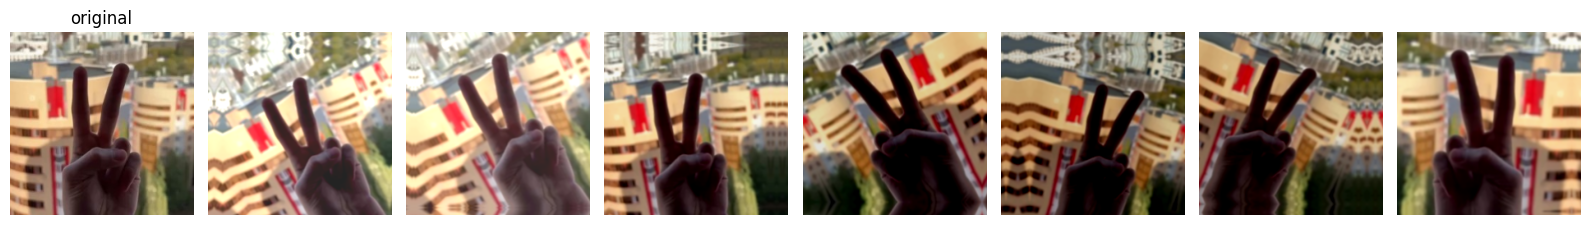

In [ ]:
# One training image and 7 augmented versions of it
img = tf.cast(X_train[:1], tf.float32)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(X_train[0]); axes[0].set_title('original'); axes[0].axis('off')
for ax in axes[1:]:
    out = augment(img, training=True)[0].numpy()
    ax.imshow(np.clip(out, 0, 255).astype('uint8')); ax.axis('off')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/augmentation.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Models

### 5.1 Baseline: simple CNN trained from scratch
Three convolution blocks on 96×96 images. It has to learn all features from my small dataset only.

In [ ]:
history, train_time, results, preds, cms, probs, n_params = {}, {}, {}, {}, {}, {}, {}


def build_baseline():
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Resizing(96, 96)(x)
    x = layers.Rescaling(1 / 255.0)(x)
    for filters in (16, 32, 64):
        x = layers.Conv2D(filters, 3, padding='same', activation='relu')(x)
        x = layers.MaxPooling2D()(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.4)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(inputs, outputs, name='baseline_cnn')


def train(model, name, epochs, lr=1e-3, monitor='val_loss', patience=5):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    stop = keras.callbacks.EarlyStopping(monitor=monitor, patience=patience, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=[stop], verbose=2)
    train_time[name] = time.time() - t0
    history[name] = h.history
    probs[name] = model.predict(test_ds, verbose=0)   # test predictions of the best epoch
    n_params[name] = model.count_params()


baseline = build_baseline()
baseline.summary()
train(baseline, 'Baseline CNN', EPOCHS_BASELINE)

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resizing_2 (Resizing)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 96, 96, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 48, 48, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 48, 48, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       589,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 613,667 (2.34 MB)

 Trainable params: 613,667 (2.34 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
10/10 - 3s - 256ms/step - accuracy: 0.3460 - loss: 1.1070 - val_accuracy: 0.3333 - val_loss: 1.0863
Epoch 2/20
10/10 - 0s - 46ms/step - accuracy: 0.5397 - loss: 0.9494 - val_accuracy: 0.6381 - val_loss: 0.8819
Epoch 3/20
10/10 - 0s - 32ms/step - accuracy: 0.6635 - loss: 0.7506 - val_accuracy: 0.6095 - val_loss: 0.6584
Epoch 4/20
10/10 - 1s - 62ms/step - accuracy: 0.7651 - loss: 0.5438 - val_accuracy: 0.6000 - val_loss: 1.4282
Epoch 5/20
10/10 - 0s - 30ms/step - accuracy: 0.7016 - loss: 0.6134 - val_accuracy: 0.3429 - val_loss: 1.1612
Epoch 6/20
10/10 - 0s - 40ms/step - accuracy: 0.8159 - loss: 0.3863 - val_accuracy: 0.7143 - val_loss: 0.7010
Epoch 7/20
10/10 - 0s - 29ms/step - accuracy: 0.8444 - loss: 0.3854 - val_accuracy: 0.5524 - val_loss: 0.9670
Epoch 8/20
10/10 - 0s - 34ms/step - accuracy: 0.8603 - loss: 0.3402 - val_accuracy: 0.7714 - val_loss: 0.5718
Epoch 9/20
10/10 - 0s - 35ms/step - accuracy: 0.8921 - loss: 0.3218 - val_accuracy: 0.6000 - val_loss: 1.0385
Epoch 10/

### 5.2 Transfer learning, step 1: frozen MobileNetV2
MobileNetV2 pretrained on ImageNet is used as a frozen feature extractor. Only a new classification head is trained on my data.

In [ ]:
def build_transfer():
    base = keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                          include_top=False, weights=WEIGHTS)
    base.trainable = False
    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inputs)
    x = layers.Rescaling(1 / 127.5, offset=-1)(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return keras.Model(inputs, outputs, name='mobilenetv2_transfer'), base


transfer, base = build_transfer()
train(transfer, 'MobileNetV2 (frozen)', EPOCHS_TRANSFER)

Epoch 1/12
10/10 - 7s - 679ms/step - accuracy: 0.4794 - loss: 1.0615 - val_accuracy: 0.4000 - val_loss: 1.1628
Epoch 2/12
10/10 - 1s - 80ms/step - accuracy: 0.8095 - loss: 0.5351 - val_accuracy: 0.4952 - val_loss: 1.3757
Epoch 3/12
10/10 - 1s - 79ms/step - accuracy: 0.9175 - loss: 0.3290 - val_accuracy: 0.4190 - val_loss: 1.3239
Epoch 4/12
10/10 - 1s - 82ms/step - accuracy: 0.9714 - loss: 0.1955 - val_accuracy: 0.4571 - val_loss: 1.4499
Epoch 5/12
10/10 - 1s - 133ms/step - accuracy: 0.9746 - loss: 0.1472 - val_accuracy: 0.3714 - val_loss: 1.4231
Epoch 6/12
10/10 - 1s - 96ms/step - accuracy: 0.9873 - loss: 0.1107 - val_accuracy: 0.3810 - val_loss: 1.4456


### 5.3 Transfer learning, step 2: fine-tuning
Frozen ImageNet features describe the whole scene, so a head trained on them can use the background instead of the hand. In this step the top layers of MobileNetV2 are unfrozen and trained with a small learning rate, so the features can adapt to hand shape. The best epoch is chosen by validation accuracy.

In [ ]:
base.trainable = True
for layer in base.layers[:100]:
    layer.trainable = False          # keep the early, generic layers frozen
print('Trainable layers in the base:', sum(l.trainable for l in base.layers), 'of', len(base.layers))

train(transfer, 'MobileNetV2 (fine-tuned)', EPOCHS_FINETUNE, lr=5e-5, monitor='val_accuracy', patience=8)

Trainable layers in the base: 54 of 154
Epoch 1/25
10/10 - 14s - 1s/step - accuracy: 0.8508 - loss: 0.4805 - val_accuracy: 0.5619 - val_loss: 1.4930
Epoch 2/25
10/10 - 1s - 126ms/step - accuracy: 0.9905 - loss: 0.1205 - val_accuracy: 0.6476 - val_loss: 1.6443
Epoch 3/25
10/10 - 1s - 124ms/step - accuracy: 1.0000 - loss: 0.0368 - val_accuracy: 0.6667 - val_loss: 1.6608
Epoch 4/25
10/10 - 1s - 115ms/step - accuracy: 1.0000 - loss: 0.0148 - val_accuracy: 0.6667 - val_loss: 1.6655
Epoch 5/25
10/10 - 1s - 115ms/step - accuracy: 1.0000 - loss: 0.0211 - val_accuracy: 0.6667 - val_loss: 1.7137
Epoch 6/25
10/10 - 1s - 127ms/step - accuracy: 1.0000 - loss: 0.0088 - val_accuracy: 0.6667 - val_loss: 1.7202
Epoch 7/25
10/10 - 1s - 116ms/step - accuracy: 1.0000 - loss: 0.0070 - val_accuracy: 0.6667 - val_loss: 1.7127
Epoch 8/25
10/10 - 1s - 123ms/step - accuracy: 1.0000 - loss: 0.0090 - val_accuracy: 0.6667 - val_loss: 1.6972
Epoch 9/25
10/10 - 1s - 127ms/step - accuracy: 1.0000 - loss: 0.0093 - val

## 6. Evaluation

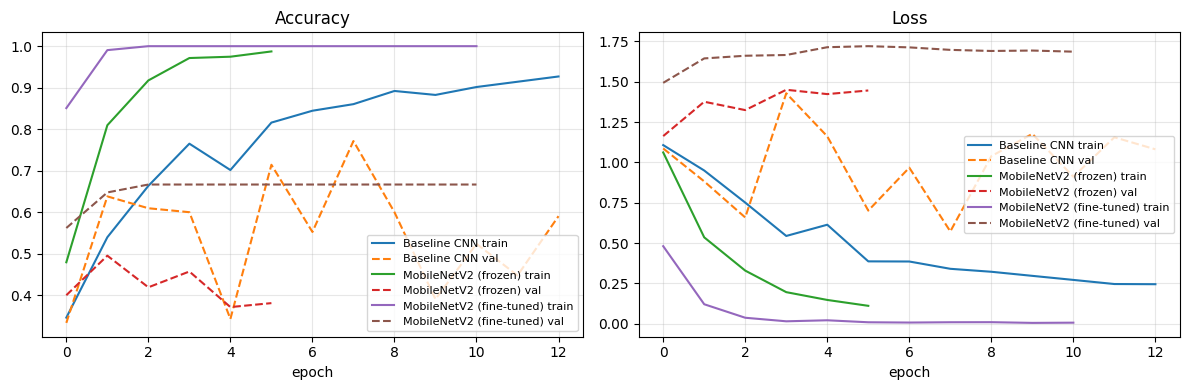

In [ ]:
# Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in history.items():
    axes[0].plot(h['accuracy'], label=f'{name} train')
    axes[0].plot(h['val_accuracy'], '--', label=f'{name} val')
    axes[1].plot(h['loss'], label=f'{name} train')
    axes[1].plot(h['val_loss'], '--', label=f'{name} val')
axes[0].set_title('Accuracy'); axes[1].set_title('Loss')
for ax in axes:
    ax.set_xlabel('epoch'); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

===== Baseline CNN =====
              precision    recall  f1-score   support

       peace      1.000     0.829     0.906        35
        stop      1.000     1.000     1.000        35
   thumbs_up      0.854     1.000     0.921        35

    accuracy                          0.943       105
   macro avg      0.951     0.943     0.942       105
weighted avg      0.951     0.943     0.942       105

===== MobileNetV2 (frozen) =====
              precision    recall  f1-score   support

       peace      0.103     0.114     0.108        35
        stop      1.000     0.800     0.889        35
   thumbs_up      0.000     0.000     0.000        35

    accuracy                          0.305       105
   macro avg      0.368     0.305     0.332       105
weighted avg      0.368     0.305     0.332       105

===== MobileNetV2 (fine-tuned) =====
              precision    recall  f1-score   support

       peace      0.452     0.800     0.577        35
        stop      1.000     0.829 

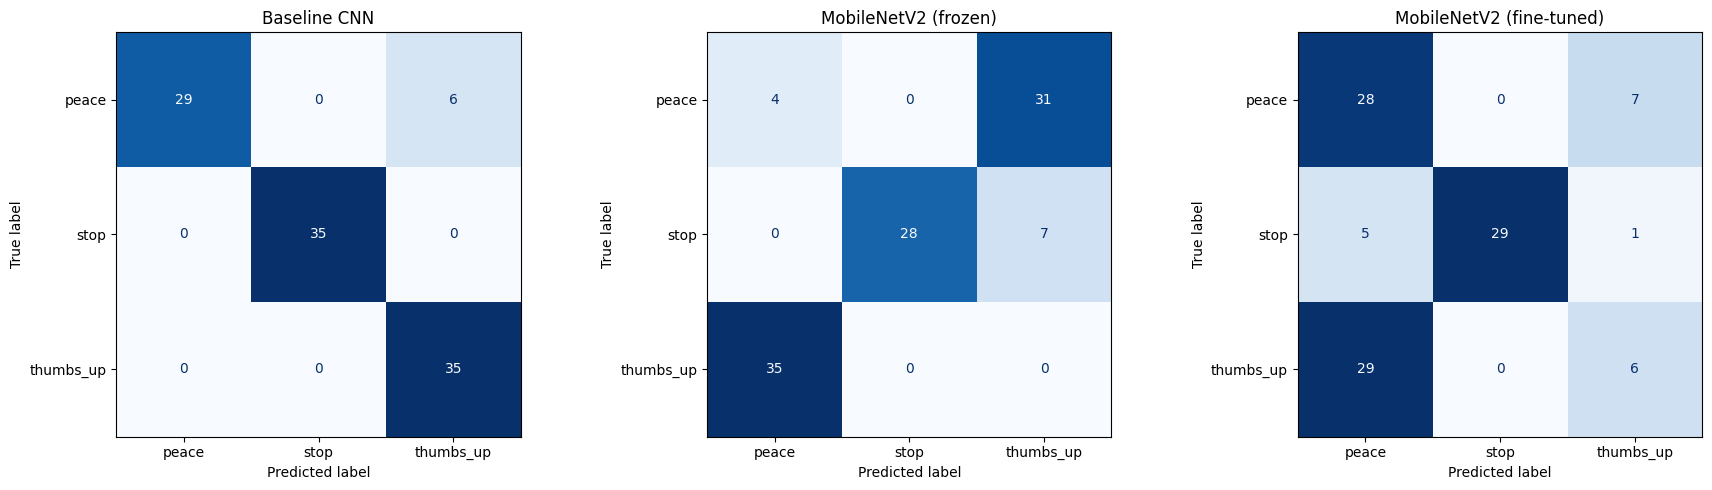

In [ ]:
def evaluate(name):
    pred = probs[name].argmax(axis=1)
    labels = list(range(NUM_CLASSES))
    acc = accuracy_score(y_test, pred)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, labels=labels,
                                                  average='macro', zero_division=0)
    results[name] = {'Accuracy': acc, 'Precision': p, 'Recall': r, 'F1-score': f1}
    preds[name] = pred
    cms[name] = confusion_matrix(y_test, pred, labels=labels)
    print(f'===== {name} =====')
    print(classification_report(y_test, pred, labels=labels, target_names=CLASS_NAMES,
                                digits=3, zero_division=0))


for name in history:
    evaluate(name)

fig, axes = plt.subplots(1, len(cms), figsize=(6 * len(cms), 5))
for ax, (name, cm) in zip(axes, cms.items()):
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

                          Accuracy  Precision  Recall  F1-score  Parameters  \
Baseline CNN                0.9429     0.9512  0.9429    0.9424      613667   
MobileNetV2 (frozen)        0.3048     0.3675  0.3048    0.3323     2261827   
MobileNetV2 (fine-tuned)    0.6000     0.6267  0.6000    0.5762     2261827   

                          Train time (s)  
Baseline CNN                         7.4  
MobileNetV2 (frozen)                11.7  
MobileNetV2 (fine-tuned)            28.0  


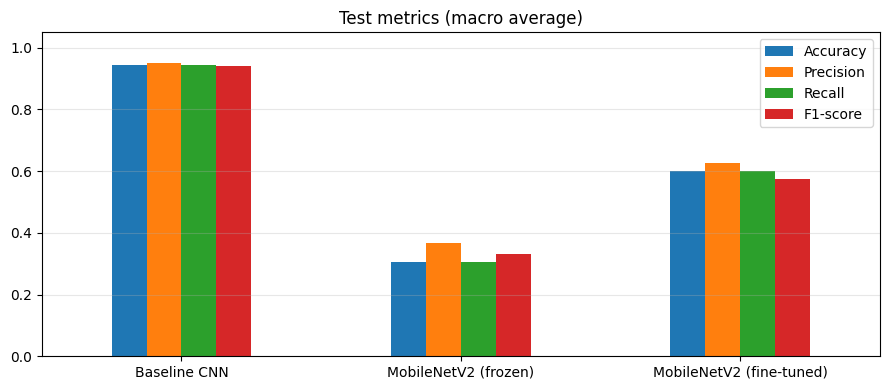

In [ ]:
# Comparison table
results_df = pd.DataFrame(results).T
results_df['Parameters'] = [n_params[n] for n in results_df.index]
results_df['Train time (s)'] = [round(train_time[n], 1) for n in results_df.index]
results_df.to_csv(f'{OUT_DIR}/results.csv')
print(results_df.round(4))

results_df[['Accuracy', 'Precision', 'Recall', 'F1-score']].plot.bar(figsize=(9, 4), rot=0)
plt.ylim(0, 1.05); plt.grid(axis='y', alpha=0.3); plt.title('Test metrics (macro average)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/comparison.png', dpi=150, bbox_inches='tight')
plt.show()

Baseline CNN: 6 wrong out of 105 test images


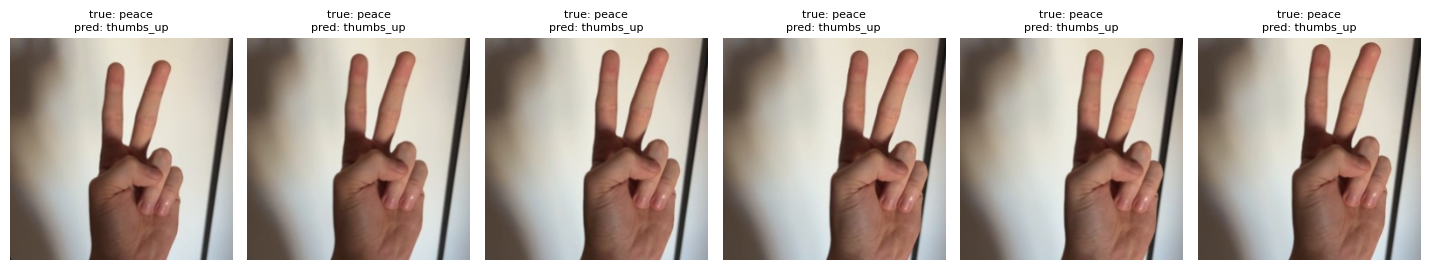

In [ ]:
# Error analysis: test images the best model (highest F1) got wrong
best = results_df['F1-score'].idxmax()
wrong = np.where(preds[best] != y_test)[0]
print(f'{best}: {len(wrong)} wrong out of {len(y_test)} test images')
if len(wrong) > 0:
    show = wrong[:8]
    fig, axes = plt.subplots(1, len(show), figsize=(2.4 * len(show), 2.8), squeeze=False)
    for ax, i in zip(axes[0], show):
        ax.imshow(X_test[i]); ax.axis('off')
        ax.set_title(f'true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[preds[best][i]]}', fontsize=8)
    plt.tight_layout()
    plt.savefig(f'{OUT_DIR}/errors.png', dpi=150, bbox_inches='tight')
    plt.show()

## 7. Save the dataset and print a summary for the report

In [ ]:
zip_path = shutil.make_archive(f'{PROJECT_DIR}/dataset', 'zip', DATASET_DIR)
print('Dataset saved to:', zip_path)
print('Figures saved to:', OUT_DIR)

print('\n=========== REPORT SUMMARY ===========')
print('Classes:', CLASS_NAMES)
print('Total images:', len(df))
print(df.groupby('label').agg(images=('path', 'count'), videos=('video', 'nunique')).to_string())
print('\nSplit (images):')
print(pd.crosstab(df.label, df.split).to_string())
print('\nResults on the test set:')
print(results_df.round(4).to_string())
for name, cm in cms.items():
    print(f'\nConfusion matrix, {name} (rows = true, columns = predicted, order = {CLASS_NAMES}):')
    print(cm)
print('\nEpochs trained:', {n: len(h['loss']) for n, h in history.items()})
print('Best model:', best, '| wrong predictions:', len(wrong), 'of', len(y_test))
print('Best validation accuracy:', {n: round(max(h['val_accuracy']), 4) for n, h in history.items()})

Dataset saved to: /content/drive/MyDrive/cv_assignment/dataset.zip
Figures saved to: /content/drive/MyDrive/cv_assignment/outputs

=========== REPORT SUMMARY ===========
Classes: ['peace', 'stop', 'thumbs_up']
Total images: 525
           images  videos
label                    
peace         175       5
stop          175       5
thumbs_up     175       5

Split (images):
split      test  train  val
label                      
peace        35    105   35
stop         35    105   35
thumbs_up    35    105   35

Results on the test set:
                          Accuracy  Precision  Recall  F1-score  Parameters  Train time (s)
Baseline CNN                0.9429     0.9512  0.9429    0.9424      613667             7.4
MobileNetV2 (frozen)        0.3048     0.3675  0.3048    0.3323     2261827            11.7
MobileNetV2 (fine-tuned)    0.6000     0.6267  0.6000    0.5762     2261827            28.0

Confusion matrix, Baseline CNN (rows = true, columns = predicted, order = ['peace', 'stop'

In [ ]:
import os, shutil, zipfile
from google.colab import files

assert os.path.isdir('/content/dataset'), 'Runtime was reset: press Run all first'
shutil.make_archive('/content/dataset', 'zip', '/content/dataset')

names = [n for n in zipfile.ZipFile('/content/dataset.zip').namelist() if n.endswith('.jpg')]
for c in ['peace', 'stop', 'thumbs_up']:
    print(c, sum(n.startswith(c + '/') for n in names))

files.download('/content/dataset.zip')

peace 175
stop 175
thumbs_up 175


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>